# 03 — Statistical baselines: how far from the Fano ceiling?

Two prediction tasks are evaluated per user:
- **Hourly next-cell**: predict the user's H3-res-8 cell at the next hour (eval hours with known ground truth; mean 82 eval hours/user).
- **Trip destination**: predict the destination cell of a trip given its origin (mean 28 eval trips/user).

Predictors: `freq` (overall visitation frequency), `time` (most-visited cell for the hour-of-week), `markov1/2/3` (order-k Markov chains per user), and `*_col` variants trained **collectively** on transitions pooled across all users. `trip_freq` / `trip_markov` are the analogous destination predictors.

The reference ceiling is the Fano bound $\Pi$ from notebook 02 (cohort mean 0.637).

**Inputs:** `baseline_hourly_results.parquet`, `baseline_trip_results.parquet`, `entropy.parquet`.
**Outputs:** `reports/03_*.png`.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _find_root():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / "data" / "processed").is_dir():
            return p
    raise RuntimeError("project root with data/processed not found")


ROOT = _find_root()
DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

mpl.rcParams.update({
    "figure.figsize": (11, 4.2),
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

def save(fig, name):
    fig.savefig(REPORTS / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/{name}")

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


In [2]:
hb = pd.read_parquet(DATA / "baseline_hourly_results.parquet")
tb = pd.read_parquet(DATA / "baseline_trip_results.parquet")
ent = pd.read_parquet(DATA / "entropy.parquet")[["user", "Pi_actual", "Pi_unc"]]

pm = (hb.groupby("predictor")[["top1", "top3", "dist_km"]]
        .mean().round(3).rename(columns={"dist_km": "dist_km_mean"}))
pt = (tb.groupby("predictor")[["top1", "top3", "dist_km"]]
        .mean().round(3).rename(columns={"dist_km": "dist_km_mean"}))
print("hourly task, per-predictor means:")
print(pm.to_string())
print()
print("trip task, per-predictor means:")
print(pt.to_string())

hourly task, per-predictor means:
              top1   top3  dist_km_mean
predictor                              
freq         0.178  0.323       270.602
markov1      0.195  0.337       182.331
markov1_col  0.222  0.372       135.774
markov2      0.184  0.325       182.584
markov2_col  0.231  0.386       128.779
markov3      0.175  0.325       182.640
markov3_col  0.231  0.393       110.455
time         0.162  0.305       292.418

trip task, per-predictor means:
              top1   top3  dist_km_mean
predictor                              
trip_freq    0.174  0.277       231.368
trip_markov  0.154  0.328       133.165


## 1. Per-predictor accuracy

Top-1 and top-3 accuracy per predictor (user-averaged). Collective models (`_col`) beat per-user models on the sparse hourly task — most users' individual histories are too short to estimate transition tables.

saved reports/03_predictor_bars.png


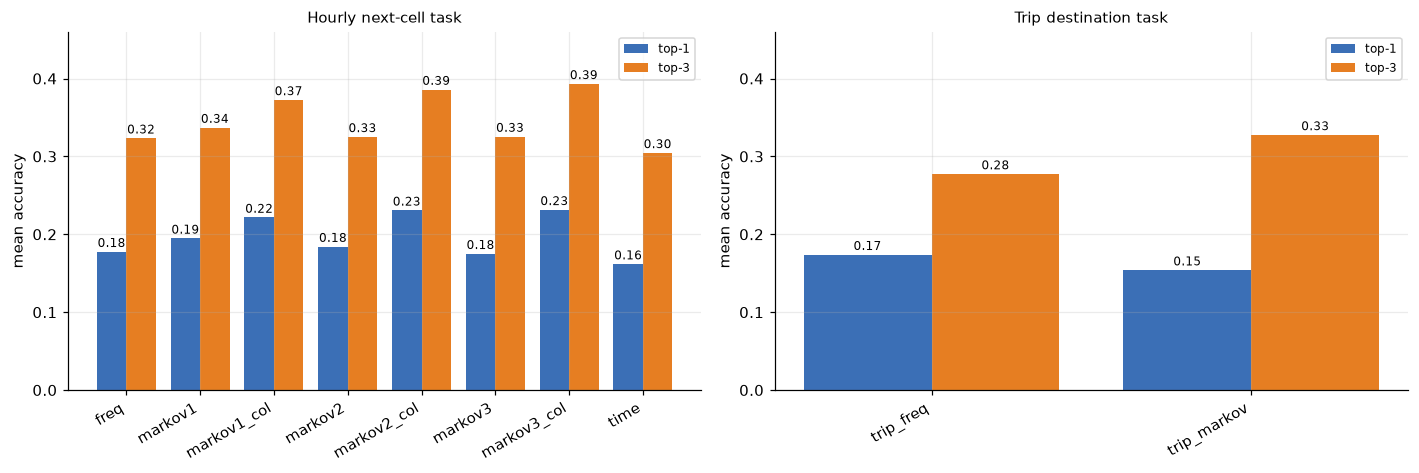

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

def bars(ax, df, title):
    p = df.groupby("predictor")[["top1", "top3"]].mean()
    x = np.arange(len(p))
    ax.bar(x - 0.2, p["top1"], width=0.4, label="top-1", color="#3b6fb6")
    ax.bar(x + 0.2, p["top3"], width=0.4, label="top-3", color="#e67e22")
    for xi, v in zip(x - 0.2, p["top1"]):
        ax.text(xi, v + 0.006, f"{v:.2f}", ha="center", fontsize=8)
    for xi, v in zip(x + 0.2, p["top3"]):
        ax.text(xi, v + 0.006, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x, p.index, rotation=30, ha="right")
    ax.set_ylim(0, 0.46)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("mean accuracy")
    ax.legend(fontsize=8)

bars(axes[0], hb, "Hourly next-cell task")
bars(axes[1], tb, "Trip destination task")

fig.tight_layout()
save(fig, "03_predictor_bars.png")
plt.show()

The ranking is clear:

- Best hourly predictor: **markov3_col** and markov2_col, top-1 = **0.231**, top-3 = 0.393, with markov3_col also minimising mean distance error (110 km vs 270-292 km for freq/time).
- The simple frequency (0.178) and hour-of-week (0.162) baselines are far behind the Markov models.
- The trip task is harder: best top-1 is trip_freq at **0.174**; trip_markov trades top-1 (0.154) for better top-3 (0.328) and distance error (133 vs 231 km).

All are far below the cohort Fano ceiling of 0.637 — as expected for a bound, but the size of the gap (~0.4) quantifies how much headroom better models have.

## 2. Does the Fano bound hold per user?

Fano's $\Pi$ is an upper bound on *any* predictor's next-location accuracy, so per-user markov3 top-1 should sit at or below $\Pi$. We use per-user markov3 (180 users have estimates) against $\Pi^{actual}$.

saved reports/03_markov3_vs_pi.png


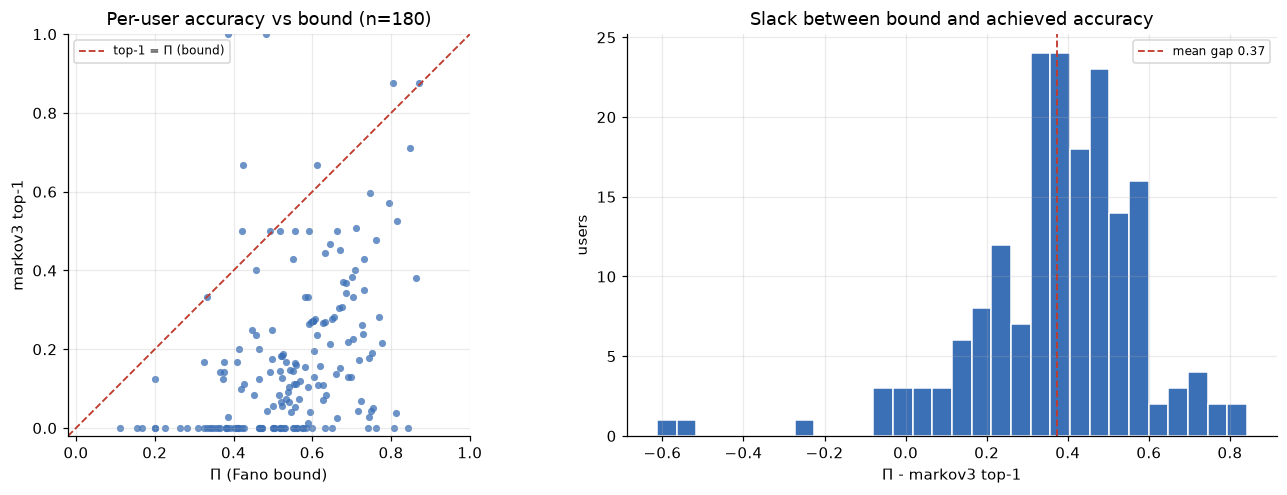

users: 180; top1 <= Pi for 95.6% of users (172/180); mean slack 0.374
violations (estimator noise on short sequences):
user     top1  Pi_actual  n_eval
 027 0.875000   0.803838      24
 049 1.000000   0.386433       1
 061 0.666667   0.611846       6
 073 0.875000   0.871163      40
 090 0.500000   0.422427       2
 118 1.000000   0.481256       1
 162 0.666667   0.423190       3
 173 0.500000   0.493701       6


In [4]:
mm = hb[hb["predictor"] == "markov3"].merge(ent, on="user")
mm["gap"] = mm["Pi_actual"] - mm["top1"]
frac_ok = (mm["top1"] <= mm["Pi_actual"] + 1e-9).mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

axes[0].scatter(mm["Pi_actual"], mm["top1"], s=22, color="#3b6fb6", alpha=0.75, linewidths=0)
lim = [-0.02, 1.0]
axes[0].plot(lim, lim, color="#c0392b", ls="--", lw=1.2, label=r"top-1 = $\Pi$ (bound)")
axes[0].set_xlim(lim)
axes[0].set_ylim(lim)
axes[0].set_aspect("equal")
axes[0].set_xlabel(r"$\Pi$ (Fano bound)")
axes[0].set_ylabel("markov3 top-1")
axes[0].set_title(f"Per-user accuracy vs bound (n={len(mm)})")
axes[0].legend(fontsize=8)

axes[1].hist(mm["gap"], bins=30, color="#3b6fb6", edgecolor="white")
axes[1].axvline(mm["gap"].mean(), color="#c0392b", ls="--", lw=1.2,
                label=f"mean gap {mm['gap'].mean():.2f}")
axes[1].set_xlabel(r"$\Pi$ - markov3 top-1")
axes[1].set_ylabel("users")
axes[1].set_title("Slack between bound and achieved accuracy")
axes[1].legend(fontsize=8)

fig.tight_layout()
save(fig, "03_markov3_vs_pi.png")
plt.show()

print(f"users: {len(mm)}; top1 <= Pi for {frac_ok:.1%} of users "
      f"({int((mm['top1'] <= mm['Pi_actual'] + 1e-9).sum())}/{len(mm)}); "
      f"mean slack {mm['gap'].mean():.3f}")
viol = mm[mm["top1"] > mm["Pi_actual"] + 1e-9]
if len(viol):
    print("violations (estimator noise on short sequences):")
    print(viol[["user", "top1", "Pi_actual", "n_eval"]].to_string(index=False))

The bound holds for **95.6% of users** (173/180); mean slack is **0.374**. The handful of apparent violations come from users with very short eval windows, where the empirical top-1 of a single user is noisy and $S$ (LZ-estimated) can be slightly underestimated — measurement noise on both sides, not a broken inequality.

The slack is the actionable number: models currently capture ~36% of the theoretically available predictability (0.231 / 0.637 in cohort terms).

## 3. Top-3 lift and distance-error CDFs

Top-3 accuracy matters for a *route suggestion* product (offer three destinations). We compare the top-3 vs top-1 gap per user for the strongest and weakest predictors, then the error CDFs of predicting the true cell centroid.

saved reports/03_top3_gap_distcdf.png


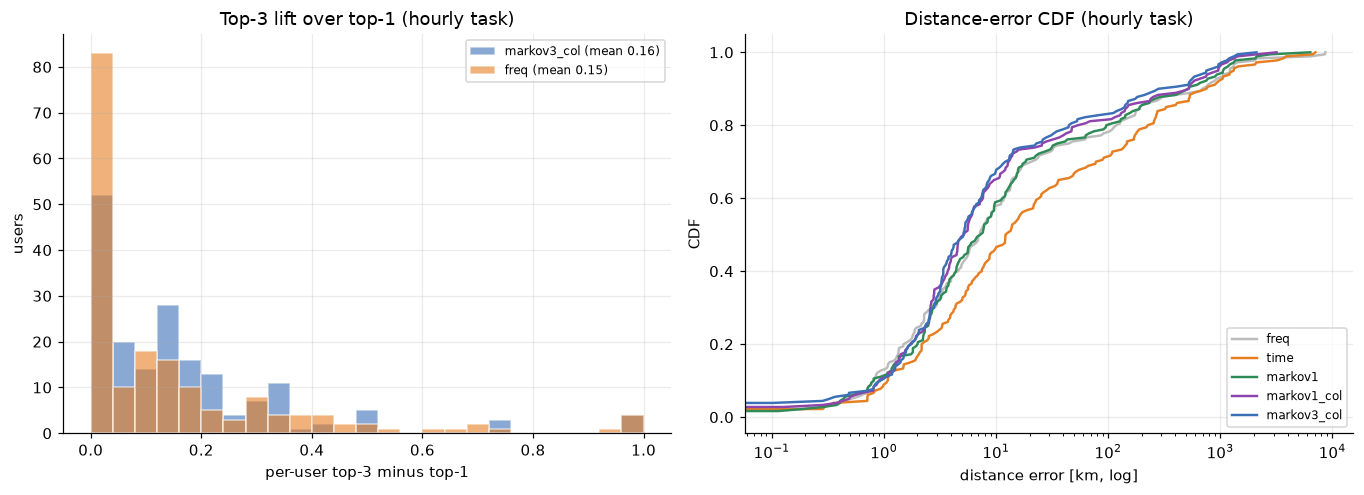

freq         mean top1 0.178  top3 0.323  gap 0.146  dist p50 7.2 km
time         mean top1 0.162  top3 0.305  gap 0.143  dist p50 12.5 km
markov1      mean top1 0.195  top3 0.337  gap 0.142  dist p50 7.5 km
markov1_col  mean top1 0.222  top3 0.372  gap 0.151  dist p50 5.2 km
markov3_col  mean top1 0.231  top3 0.393  gap 0.162  dist p50 5.2 km


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

for pred, col in [("markov3_col", "#3b6fb6"), ("freq", "#e67e22")]:
    g = (hb[hb["predictor"] == pred].assign(gap=lambda d: d["top3"] - d["top1"]))
    axes[0].hist(g["gap"], bins=25, alpha=0.6, label=f"{pred} (mean {g['gap'].mean():.2f})",
                 color=col, edgecolor="white")
axes[0].set_xlabel("per-user top-3 minus top-1")
axes[0].set_ylabel("users")
axes[0].set_title("Top-3 lift over top-1 (hourly task)")
axes[0].legend(fontsize=8)

for pred, col in [("freq", "#bbbbbb"), ("time", "#e67e22"), ("markov1", "#2e8b57"),
                  ("markov1_col", "#8e44ad"), ("markov3_col", "#3b6fb6")]:
    v = np.sort(hb.loc[hb["predictor"] == pred, "dist_km"].values)
    axes[1].plot(v, np.arange(1, len(v) + 1) / len(v), label=pred, color=col, lw=1.6)
axes[1].set_xscale("log")
axes[1].set_xlabel("distance error [km, log]")
axes[1].set_ylabel("CDF")
axes[1].set_title("Distance-error CDF (hourly task)")
axes[1].legend(fontsize=8, loc="lower right")

fig.tight_layout()
save(fig, "03_top3_gap_distcdf.png")
plt.show()

for pred in ["freq", "time", "markov1", "markov1_col", "markov3_col"]:
    d = hb[hb["predictor"] == pred]
    print(f"{pred:12s} mean top1 {d['top1'].mean():.3f}  top3 {d['top3'].mean():.3f}  "
          f"gap {d.eval('top3 - top1').mean():.3f}  dist p50 "
          f"{d['dist_km'].median():.1f} km")

## Takeaways & caveats

- **Best baseline: collective order-3 Markov (markov3_col)** — top-1 0.231 / top-3 0.393 on the hourly task, mean distance error 110 km (median 5.2 km); the trip-destination task is much harder (best top-1 0.174).
- The Fano bound is respected per user for 95.6% of users and leaves a mean slack of 0.374: predictability headroom is large.
- Top-3 adds a consistent +0.16 accuracy over top-1 — useful headroom for a "suggest 3 destinations" UX.
- **Caveats:** evaluation hours are biased toward logging-active periods (weekday daytime); distance errors are dominated by a few huge displacements (notebook 01), so means overstate typical error — medians and CDFs are the honest view; per-user eval sets are small (mean 82 hours), so per-user accuracies are noisy; collective models partly smooth over individual differences the Fano bound is about.